In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [160]:
# X layout: [Square Footage]
X = np.array([1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 2000], dtype=float)
X = X.reshape(-1,1)
# y layout: [House Price]
y = np.array([150000, 165000, 180000, 210000, 220000, 240000, 265000, 270000, 285000, 320000], dtype=float)


print(f"Number of training examples (m): {X.shape[0]}")
print(f"Number of features (n): {X.shape[1]}")

# Number of training examples (m): 10
# Number of features (n): 1

Number of training examples (m): 10
Number of features (n): 1


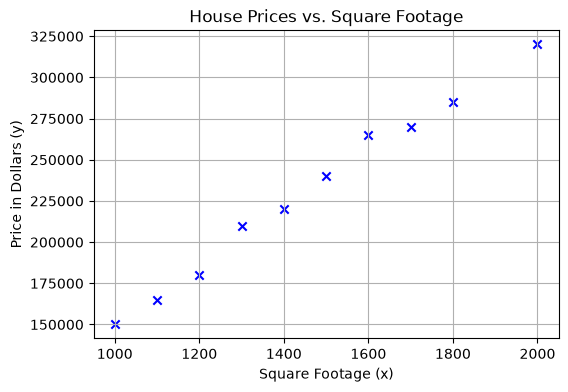

In [148]:
# We can visualize the dataset:

plt.figure(figsize=(6, 4))
plt.scatter(X, y, c='blue', marker='x')
plt.title("House Prices vs. Square Footage")
plt.xlabel("Square Footage (x)")
plt.ylabel("Price in Dollars (y)")
plt.grid(True)
plt.show()

In [149]:
# Cost Function - Mean Square error

def mean_squared_error(y_true, y_pred):
    errors = y_true - y_pred
    return np.mean(errors ** 2)

In [161]:
X = np.asarray(X, dtype=float)
y = np.asarray(y, dtype=float).reshape(-1)

# add a column of ones to the left side of your feature matrix X
X_new = np.column_stack([np.ones(X.shape[0]),X])

W = np.dot(np.linalg.inv(np.dot(X_new.T, X_new)), np.dot(X_new.T, y))

y_pred = np.dot(X_new, coefficients)

mse = mean_squared_error(y, y_pred)

print(f"Bias: {W[0]} | Weight: {W[1]}")
print(f"Mean Square Error: {mse}")

# Result: 
# Bias: -21049.78354978488 | Weight: 172.2943722943726
# Mean Square Error: 24323593.07359312


Bias: -21049.78354978488 | Weight: 172.2943722943726
Mean Square Error: 24323593.07359312


However, calculating a raw matrix inverse (np.linalg.inv) can be computationally dangerous. If two of your features are highly correlated, or if a column is filled with zeros, the matrix becomes "singular" or "non-invertible." np.linalg.inv will crash with a LinAlgError. np.linalg.lstsq handles this safely using SVD decomposition so it never crashes.

Under the hood, np.linalg.lstsq is solving what is known as the Normal Equation:

$$
\boxed{
\boldsymbol{W} = (\boldsymbol{X}^T \boldsymbol{X})^{-1}\boldsymbol{X}^T\boldsymbol{y}
}
$$

Instead of computing that matrix inverse directly, np.linalg.lstsq, a highly optimized technique called Singular Value Decomposition (SVD). It computes the "pseudo-inverse" of the features to return the weights that minimize the Mean Squared Error function.

In [151]:
X = np.asarray(X, dtype=float)
y = np.asarray(y, dtype=float).reshape(-1)

X_new = np.column_stack([np.ones(X.shape[0]),X])

coefficients, residuals, _, _ = (
    np.linalg.lstsq(X_new, y, rcond=None)
)
print(f"Bias: {coefficients[0]} | Weight: {coefficients[1]}")
print(f"Mean Square Error: {residuals[0]}")

y_pred = np.dot(X_new, coefficients)

# Result:
# Bias: -21049.783549783482 | Weight: 172.29437229437232
# Mean Square Error: 243235930.73593095

Bias: -21049.783549783482 | Weight: 172.29437229437232
Mean Square Error: 243235930.73593095


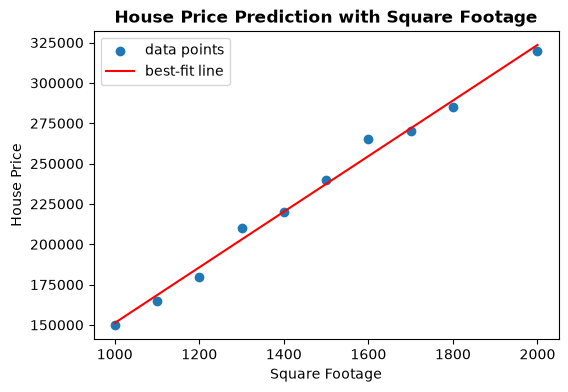

In [152]:
plt.figure(figsize=(6,4))
plt.scatter(X,y, label="data points")
plt.plot(X,y_pred, color="r", label="best-fit line")
plt.title("House Price Prediction with Square Footage", fontweight="bold")
plt.xlabel("Square Footage")
plt.ylabel("House Price")
plt.legend()
plt.show()

### **Gradient Descent**

Gradient descent is an iterative optimization algorithm that works by moving the parameters in the direction that decreases the loss.

In [ ]:
def batch_gradient_descent(X, y, learning_rate=0.01, n_iterations=1000):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n_samples, n_features = X.shape

    # Create the Design Matrix by adding the intercept column (x0 = 1)
    X_new = np.column_stack([np.ones(n_samples), X])
    # Initialize unified parameter vector W: [bias, w1, w2, ..., wn] to zeros
    W = np.zeros(n_features + 1)
    loss_history = []

    for _ in range(n_iterations):
        # compute y_pred based on y_pred = X.W
        y_pred = np.dot(X_new, W)
        error = y_pred - y

        # Calculate and store loss 
        mse = np.mean(error ** 2)
        loss_history.append(mse)

        # calculate and update new parameters
        dw = (2 / n_samples) * np.dot(X_new.T, error)
        W -= learning_rate * dw
    
    bias = W[0]
    weights = W[1:]

    return bias, weights, loss_history



In [ ]:
def stochastic_gradient_descent(X, y, learning_rate=0.01, n_epochs=50):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n_samples, n_features = X.shape

    X_new = np.column_stack([np.ones(n_samples), X])

    W = np.zeros(n_features + 1)
    loss_history = []

    for epoch in range(n_epochs):
        indices = np.random.permutation(n_samples)

        for i in indices:
            Xi = X_new[i]
            yi = y[i]

            yi_pred = np.dot(Xi, W)
            error = yi_pred - yi

            dw = 2 * error * Xi
            W -= learning_rate * dw

        epoch_y_pred = np.dot(X_new, W)
        epoch_error = epoch_y_pred - y
        epoch_loss = np.mean(epoch_error ** 2)

        loss_history.append(epoch_loss)

    bias = W[0]
    weights = W[1:]

    return bias, weights, loss_history


In [ ]:
def mini_batch_gradient_descent(X, y, learning_rate=0.01, n_epochs=50, batch_size=50):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n_samples, n_features = X.shape

    X_new = np.column_stack([np.ones(n_samples), X])

    W = np.zeros(n_features + 1)
    loss_history = []

    for epoch in range(n_epochs):
        indices = np.random.permutation(n_samples)
        X_shuffled = X_new[indices]
        y_shuffled = y[indices]

        for i in range(0, n_samples, batch_size):
            X_batch = X_shuffled[i : i + batch_size]
            y_batch = y_shuffled[i : i + batch_size]

            k, _ = X_batch.shape

            y_batch_pred = np.dot(X_batch, W)
            batch_error = y_batch_pred - y_batch

            dw = (2 / k) * np.dot(X_batch.T, batch_error)
            W -= learning_rate * dw
        
        epoch_y_pred = np.dot(X_new, W)
        epoch_error = epoch_y_pred - y
        epoch_loss = np.mean(epoch_error ** 2)

        loss_history.append(epoch_loss)

    bias = W[0]
    weights = W[1:]

    return bias, weights, loss_history        
            

            

### **Polynomial Regression**

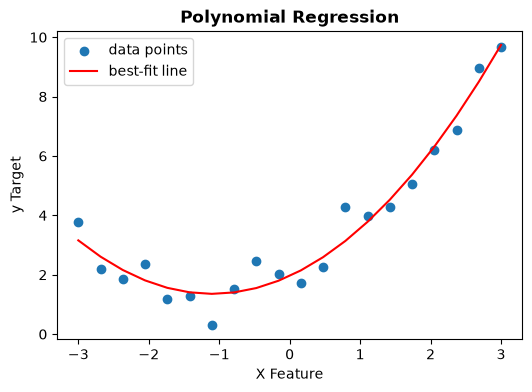

In [145]:
X = np.linspace(-3, 3, 20).reshape(-1, 1)
noise = np.random.normal(0, 0.5, size=(20, 1))
y = (0.5 * (X ** 2) + 1.0 * X + 2.0 + noise).reshape(-1)

# Stacking a 
X_poly = np.column_stack([X, X ** 2])
bias, weights, loss_history = batch_gradient_descent(X_poly, y, learning_rate=0.01, n_iterations=1000)
y_pred = X_poly @ weights + bias

plt.figure(figsize=(6,4))
plt.scatter(X,y, label="data points")
plt.plot(X,y_pred, color="r", label="best-fit line")
plt.title("Polynomial Regression", fontweight="bold")
plt.xlabel("X Feature")
plt.ylabel("y Target")
plt.legend()
plt.show()

### **Linear Regression with Regularization**

In [175]:
def _penalty(W, n_samples, lmbda=1.0, r=0.5, penalty="ridge"):
    W_no_bias = np.copy(W)
    W_no_bias[0] = 0.0

    if penalty == "ridge":
        l2_penalty = (lmbda / n_samples) * np.sum(W_no_bias **2)
        l2_grad = (2 * lmbda / n_samples) * W_no_bias
        return l2_penalty, l2_grad
    elif penalty == "lasso":
        l1_penalty = (lmbda / n_samples) * np.sum(np.abs(W_no_bias))
        l1_grad = (lmbda / n_samples) * np.sign(W_no_bias)
        return l1_penalty, l1_grad
    elif penalty == "elastic_net":
        l1 = (lmbda * r / n_samples) * np.sum(np.abs(W_no_bias))
        l2 = (lmbda * (1 - r) / (2 * n_samples)) * np.sum(W_no_bias ** 2)
        en_penalty = l1 + l2

        l1_grad = (lmbda * r / n_samples) * np.sign(W_no_bias)
        l2_grad = (2 * lmbda * (1 - r) / n_samples) * W_no_bias
        en_grad = l1_grad + l2_grad

        return en_penalty, en_grad
    else:
        raise ValueError("Penalty type not recognized")


In [176]:
def regularized_batch_gradient_descent(X, y, learning_rate=0.001, lmbda=1.0, r=0.5, n_iterations=1000, penalty="ridge"):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n_samples, n_features = X.shape

    X_new = np.column_stack([np.ones(n_samples), X])
    W = np.zeros(n_features + 1)
    loss_history = []

    for _ in range(n_iterations):
        y_pred = np.dot(X_new, W)
        error = y_pred - y

        r_penalty, r_grad = _penalty(W, n_samples, lmbda=lmbda, r=r, penalty=penalty)

        mse = np.mean(error ** 2) + r_penalty
        loss_history.append(mse)

        dw = (2 / n_samples) * np.dot(X_new.T, error) + r_grad
        W -= learning_rate * dw
    
    bias = W[0]
    weights = W[1:]

    return bias, weights, loss_history



In [190]:
X = np.array([1000, 1100, 1200, 1300, 1400, 1500, 1600, 1700, 1800, 2000], dtype=float)
X = X.reshape(-1,1)
# y layout: [House Price]
y = np.array([150000, 165000, 180000, 210000, 220000, 240000, 265000, 270000, 285000, 320000], dtype=float)

X = np.asarray(X, dtype=float)
y = np.asarray(y, dtype=float).reshape(-1)

X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)
X_scaled = (X - X_mean) / X_std

In [210]:
# With ridge penalty
b_ridge, w_ridge, lh = regularized_batch_gradient_descent(X_scaled, y, learning_rate=0.001, lmbda=1.0, n_iterations=1000, penalty="ridge")
y_ridge_pred = X_scaled @ w_ridge + b_ridge
print(f"Mean squared error of Batch GD with ridge penalty: {mean_squared_error(y, y_ridge_pred)}")

Mean squared error of Batch GD with ridge penalty: 1094027637.8526168


In [209]:
# with lasso penalty
b_lasso, w_lasso, lh = regularized_batch_gradient_descent(X_scaled, y, learning_rate=0.001, lmbda=1.0, n_iterations=1000, penalty="lasso")
y_lasso_pred = X_scaled @ w_lasso + b_lasso
print(f"Mean squared error of Batch GD with lasso penalty:{mean_squared_error(y, y_lasso_pred)}")

Mean squared error of Batch GD with lasso penalty:1043586447.3326359


In [211]:
# with elastic net penalty
b, w, lh = regularized_batch_gradient_descent(X_scaled, y, learning_rate=0.001, lmbda=1.0, n_iterations=1000, penalty="elastic_net")
y_en_pred = X_scaled @ w_lasso + b_lasso
print(f"Mean squared error of Batch GD with elastic net penalty:{mean_squared_error(y, y_en_pred)}")

Mean squared error of Batch GD with elastic net penalty:1043586447.3326359


In [212]:
b_none, w_none, lh = batch_gradient_descent(X_scaled, y, learning_rate=0.001, n_iterations=1000)
y_none_pred = X_scaled @ w_none + b_none
print(f"Mean squared error of Batch GD with no penalty:{mean_squared_error(y, y_none_pred)}")

Mean squared error of Batch GD with no penalty:1043585835.6903889


In [215]:
def r2_score(y_true, y_pred, epsilon=1e-15):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    
    y_mean = np.mean(y_true)
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_mean) ** 2)
    
    r2 = 1.0 - (ss_res / (ss_tot + epsilon))
    
    return r2

In [217]:
# Generate predictions using your trained scaled parameters
y_pred_none = X_scaled @ w_none + b_none
y_pred_ridge = X_scaled @ w_ridge + b_ridge

# Compute performance ratios
print(f"R² Score (No Penalty):  {r2_score(y, y_pred_none) * 100:.2f}%")
print(f"R² Score (Ridge Penalty): {r2_score(y, y_pred_ridge) * 100:.2f}%")

R² Score (No Penalty):  62.29%
R² Score (Ridge Penalty): 60.47%
